# Lab 1 Микитюк Антон Андреевич 2374

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from pandas.plotting import scatter_matrix
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

## 1. Выбор и описание датасета

In [2]:
wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)
df['target'] = wine.target
df['target_name'] = df['target'].map({0: 'class_0', 1: 'class_1', 2: 'class_2'})

print(f"Размер датасета: {df.shape[0]} записей, {df.shape[1]} столбцов")
print(f"\nКлассы: {wine.target_names}")
print(f"\nРаспределение по классам:")
print(df['target_name'].value_counts())

Размер датасета: 178 записей, 15 столбцов

Классы: ['class_0' 'class_1' 'class_2']

Распределение по классам:
target_name
class_1    71
class_0    59
class_2    48
Name: count, dtype: int64


In [3]:
df.head(10)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target,target_name
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0
5,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0,0,class_0
6,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0,0,class_0
7,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0,0,class_0
8,14.83,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0,0,class_0
9,13.86,1.35,2.27,16.0,98.0,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045.0,0,class_0


### Описание датасета

Предметная область: химический анализ вин, выращенных в одном регионе Италии, но сделанные из трёх разных сортов винограда

Источник данных: UCI Machine Learning Repository, датасет Wine. https://archive.ics.uci.edu/dataset/109/wine

Характер данных: данные получены в ходе химического анализа образцов вин

Задача анализа: классификация - определение сорта вина по результатам химического анализа. Три класса: class_0 (59 образцов), class_1 (71 образец), class_2 (48 образцов)

### Атрибуты датасета

| № | Атрибут | Тип | Описание |
|---|---------|-----|----------|
| 1 | alcohol | числовой (float) | Содержание алкоголя (%) |
| 2 | malic_acid | числовой (float) | Яблочная кислота (г/л) |
| 3 | ash | числовой (float) | Зольность (г/л) |
| 4 | alcalinity_of_ash | числовой (float) | Щёлочность золы (мэкв/л) |
| 5 | magnesium | числовой (float) | Магний (мг/л) |
| 6 | total_phenols | числовой (float) | Общее содержание фенолов |
| 7 | flavanoids | числовой (float) | Флавоноиды |
| 8 | nonflavanoid_phenols | числовой (float) | Нефлавоноидные фенолы |
| 9 | proanthocyanins | числовой (float) | Проантоцианины |
| 10 | color_intensity | числовой (float) | Интенсивность цвета |
| 11 | hue | числовой (float) | Оттенок |
| 12 | od280/od315_of_diluted_wines | числовой (float) | Коэффициент OD280/OD315 разбавленных вин |
| 13 | proline | числовой (float) | Пролин (мг/л) |
| 14 | target | целочисленный (int) | Класс вина (0, 1, 2) |

## 2. Статистический анализ атрибутов

In [4]:
features = wine.feature_names
df_features = df[features]

print("Сводная статистика числовых атрибутов:\n")
df_features.describe().round(2)

Сводная статистика числовых атрибутов:



,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00
mean,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89
std,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91
min,11.03,0.74,1.36,10.60,70.00,0.98,0.34,0.13,0.41,1.28,0.48,1.27,278.00
25%,12.36,1.60,2.21,17.20,88.00,1.74,1.20,0.27,1.25,3.22,0.78,1.94,500.50
50%,13.05,1.87,2.36,19.50,98.00,2.36,2.13,0.34,1.56,4.69,0.96,2.78,673.50
75%,13.68,3.08,2.56,21.50,107.00,2.80,2.88,0.44,1.95,6.20,1.12,3.17,985.00
max,14.83,5.80,3.23,30.00,162.00,3.88,5.08,0.66,3.58,13.00,1.71,4.00,1680.00


### 2.1. Среднее значение и стандартное отклонение (СКО)

In [5]:
stats = pd.DataFrame({
    'Минимум': df_features.min(),
    'Максимум': df_features.max(),
    'Среднее': df_features.mean(),
    'СКО': df_features.std()
}).round(3)

print("Среднее значение и СКО каждого атрибута:\n")
stats

Среднее значение и СКО каждого атрибута:



,Минимум,Максимум,Среднее,СКО
alcohol,11.03,14.83,13.001,0.812
malic_acid,0.74,5.80,2.336,1.117
ash,1.36,3.23,2.367,0.274
alcalinity_of_ash,10.60,30.00,19.495,3.340
magnesium,70.00,162.00,99.742,14.282
total_phenols,0.98,3.88,2.295,0.626
flavanoids,0.34,5.08,2.029,0.999
nonflavanoid_phenols,0.13,0.66,0.362,0.124
proanthocyanins,0.41,3.58,1.591,0.572
color_intensity,1.28,13.00,5.058,2.318


### 2.2. Гистограммы распределения значений

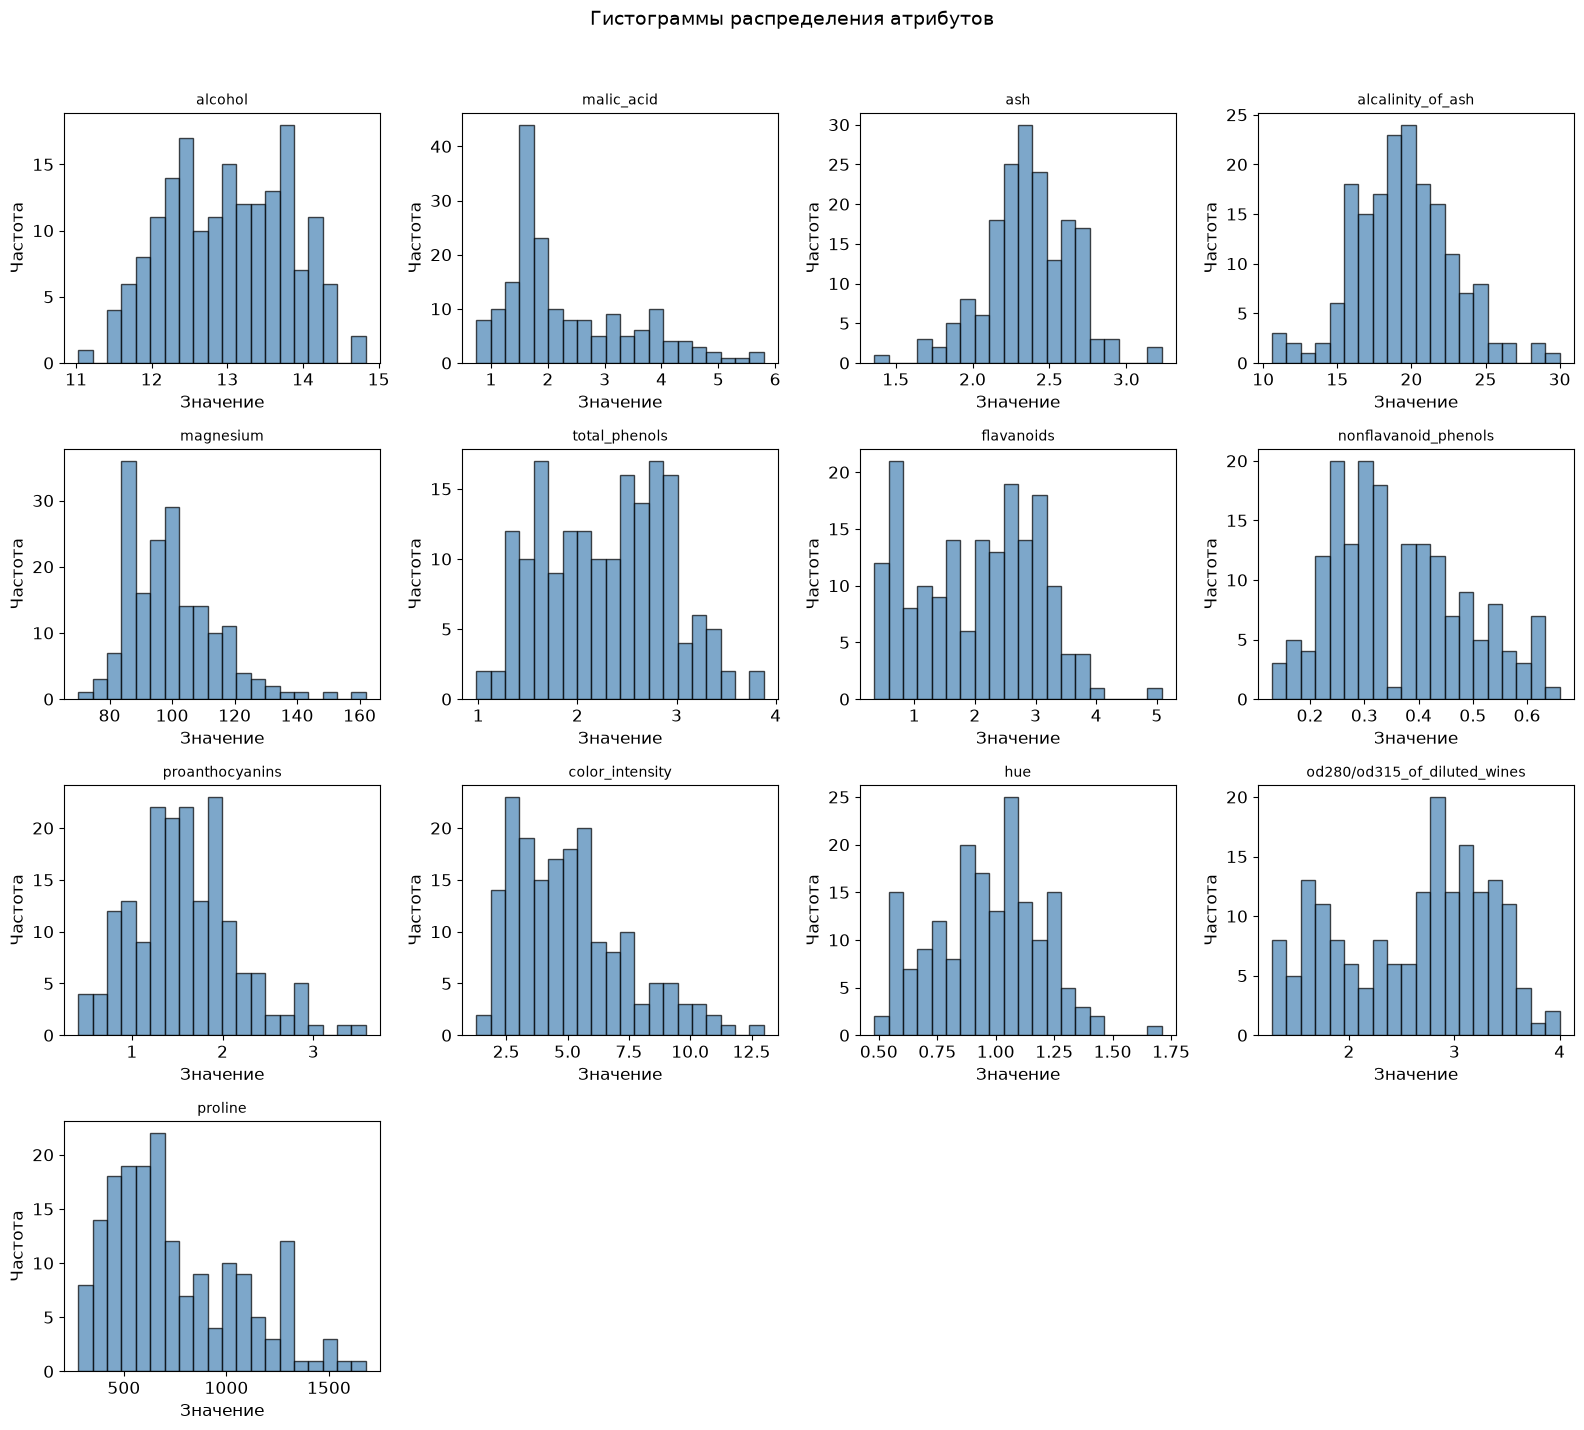

In [6]:
fig, axes = plt.subplots(4, 4, figsize=(16, 14))
axes = axes.flatten()

for i, col in enumerate(features):
    axes[i].hist(df[col], bins=20, color='steelblue', edgecolor='black', alpha=0.7)
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel('Значение')
    axes[i].set_ylabel('Частота')

for j in range(len(features), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Гистограммы распределения атрибутов', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### 2.3. Анализ выбросов

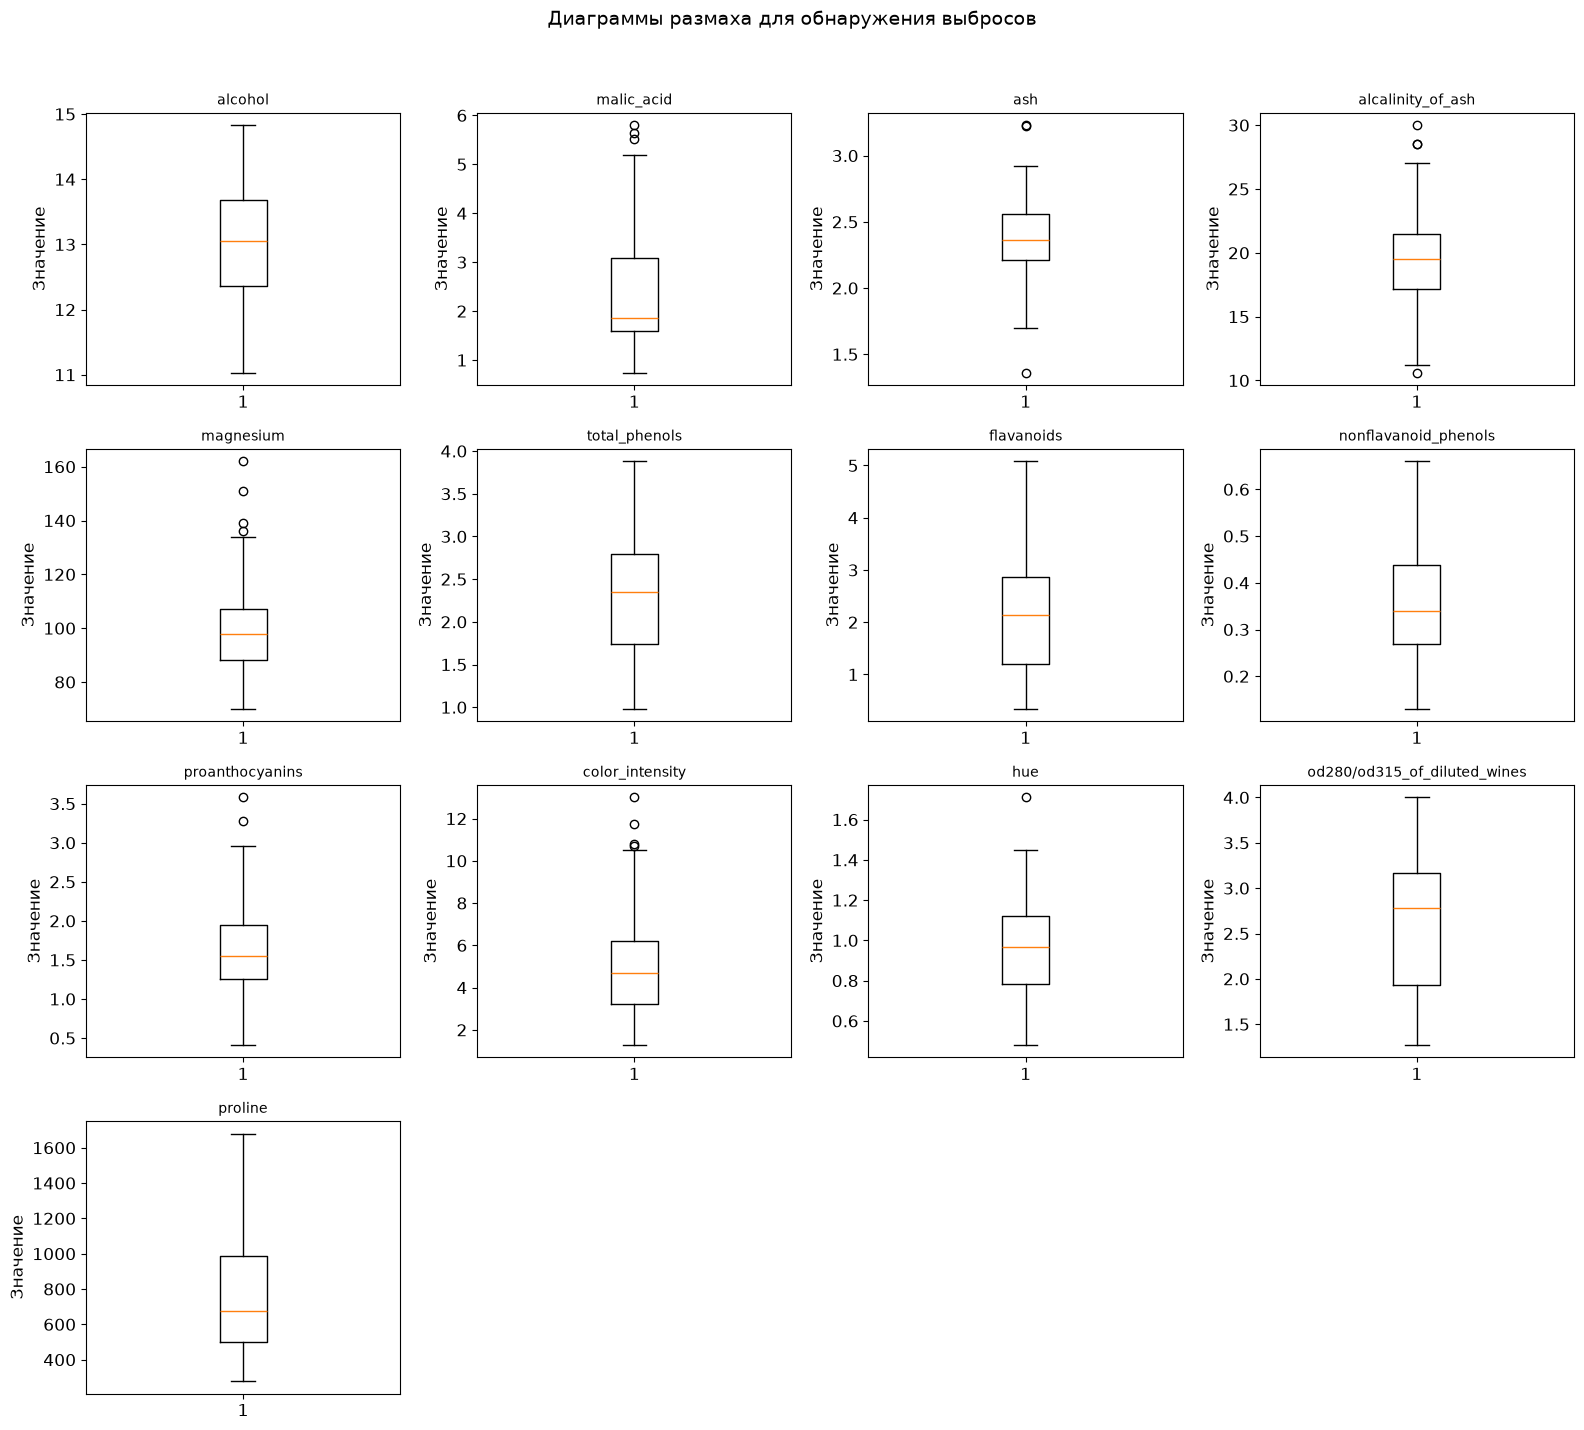

In [7]:
fig, axes = plt.subplots(4, 4, figsize=(16, 14))
axes = axes.flatten()

for i, col in enumerate(features):
    axes[i].boxplot(df[col], vert=True)
    axes[i].set_title(col, fontsize=10)
    axes[i].set_ylabel('Значение')

for j in range(len(features), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Диаграммы размаха для обнаружения выбросов', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [8]:
print("Выбросы по методу межквартильного размаха:\n")

outlier_summary = []
for col in features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    outlier_summary.append({
        'Атрибут': col,
        'Q1': round(Q1, 2),
        'Q3': round(Q3, 2),
        'IQR': round(IQR, 2),
        'Нижняя граница': round(lower, 2),
        'Верхняя граница': round(upper, 2),
        'Кол-во выбросов': len(outliers)
    })

outlier_df = pd.DataFrame(outlier_summary)
outlier_df

Выбросы по методу межквартильного размаха:



,Атрибут,Q1,Q3,IQR,Нижняя граница,Верхняя граница,Кол-во выбросов
0,alcohol,12.36,13.68,1.32,10.39,15.65,0
1,malic_acid,1.60,3.08,1.48,-0.62,5.30,3
2,ash,2.21,2.56,0.35,1.69,3.08,3
3,alcalinity_of_ash,17.20,21.50,4.30,10.75,27.95,4
4,magnesium,88.00,107.00,19.00,59.50,135.50,4
5,total_phenols,1.74,2.80,1.06,0.16,4.39,0
6,flavanoids,1.20,2.88,1.67,-1.30,5.38,0
7,nonflavanoid_phenols,0.27,0.44,0.17,0.02,0.69,0
8,proanthocyanins,1.25,1.95,0.70,0.20,3.00,2
9,color_intensity,3.22,6.20,2.98,-1.25,10.67,4


**Анализ выбросов:**

Для обнаружения выбросов использован метод межквартильного размаха (IQR). Значение считается выбросом, если выходит за пределы от Q1 − 1.5·IQR до Q3 + 1.5·IQR

Наибольшее количество выбросов наблюдается у атрибутов magnesium, alcalinity_of_ash и color_intensity (по 4 выброса), что подтверждается их распределением. Для большинства атрибутов количество выбросов невелико, что свидетельствует о довольно чистых данных

### 2.4. Пропущенные значения

In [9]:
print("Количество пропущенных значений по каждому атрибуту:\n")

missing = df_features.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)

missing_df = pd.DataFrame({
    'Пропущенные значения': missing.values,
    '% пропусков': missing_pct.values
}, index=missing.index)

missing_df

Количество пропущенных значений по каждому атрибуту:



,Пропущенные значения,% пропусков
alcohol,0,0.0
malic_acid,0,0.0
ash,0,0.0
alcalinity_of_ash,0,0.0
magnesium,0,0.0
total_phenols,0,0.0
flavanoids,0,0.0
nonflavanoid_phenols,0,0.0
proanthocyanins,0,0.0
color_intensity,0,0.0


In [10]:
total_missing = df_features.isnull().sum().sum()
total_cells = df_features.size
print(f"Общее количество пропущенных значений: {total_missing}")
print(f"Общее количество ячеек: {total_cells}")
print(f"Процент пропущенных значений: {(total_missing / total_cells * 100):.2f}%")

Общее количество пропущенных значений: 0
Общее количество ячеек: 2314
Процент пропущенных значений: 0.00%


**Анализ пропущенных значений:**

В датасете Wine отсутствуют пропущенные значения, все 178 записей полностью заполнены по всем 13 атрибутам

Подходы к обработке пропущенных значений:
- Удаление строк - если пропусков мало (до 5%) и они случайны;
- Замена средним - для числовых атрибутов с нормальным распределением;
- Замена медианой - для числовых атрибутов с асимметричным распределением;
- Замена модой - для категориальных данных;
- Интерполяция - для временных рядов.

## 3. Корреляционный анализ

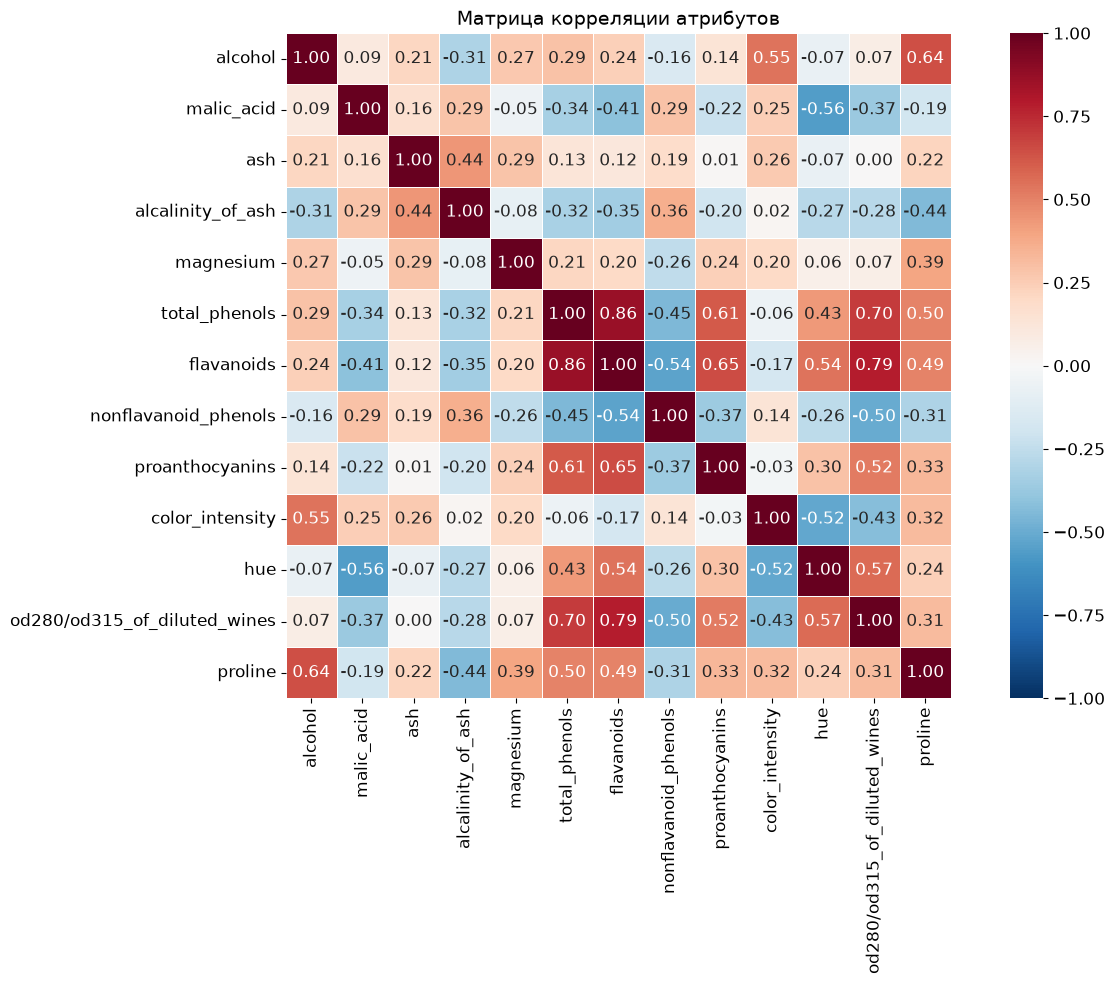

In [11]:
corr_matrix = df_features.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, linewidths=0.5, vmin=-1, vmax=1)
plt.title('Матрица корреляции атрибутов', fontsize=14)
plt.tight_layout()
plt.show()

### 3.1. Высококоррелированные атрибуты

In [12]:
pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > 0.6:
            pairs.append({
                'Атрибут 1': corr_matrix.columns[i],
                'Атрибут 2': corr_matrix.columns[j],
                'Корреляция (r)': round(r, 3),
                'Характер': 'Положительная' if r > 0 else 'Отрицательная'
            })

high_corr = pd.DataFrame(pairs).sort_values('Корреляция (r)', key=abs, ascending=False).reset_index(drop=True)
print(f"Пары атрибутов с |r| > 0.6 ({len(high_corr)} пар):\n")
high_corr

Пары атрибутов с |r| > 0.6 (6 пар):



,Атрибут 1,Атрибут 2,Корреляция (r),Характер
0,total_phenols,flavanoids,0.865,Положительная
1,flavanoids,od280/od315_of_diluted_wines,0.787,Положительная
2,total_phenols,od280/od315_of_diluted_wines,0.700,Положительная
3,flavanoids,proanthocyanins,0.653,Положительная
4,alcohol,proline,0.644,Положительная
5,total_phenols,proanthocyanins,0.612,Положительная


In [13]:
all_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        r = corr_matrix.iloc[i, j]
        all_pairs.append({
            'Атрибут 1': corr_matrix.columns[i],
            'Атрибут 2': corr_matrix.columns[j],
            'Корреляция (r)': round(r, 3)
        })

all_pairs_df = pd.DataFrame(all_pairs).sort_values('Корреляция (r)').reset_index(drop=True)
print("Топ-3 отрицательные корреляции:\n")
all_pairs_df.head(3)

Топ-3 отрицательные корреляции:



,Атрибут 1,Атрибут 2,Корреляция (r)
0,malic_acid,hue,-0.561
1,flavanoids,nonflavanoid_phenols,-0.538
2,color_intensity,hue,-0.522


**Анализ высококоррелированных атрибутов:**

Все 6 пар с |r| > 0.6 имеют положительную корреляцию. Самые сильные:
- **total_phenols и flavanoids** (r = 0.865) - флавоноиды являются подгруппой фенолов, поэтому их содержание закономерно связано;
- **flavanoids и od280/od315** (r = 0.787) - оптическая плотность при 280 нм чувствительна к фенольным соединениям;
- **total_phenols и od280/od315** (r = 0.700) - аналогичная биохимическая связь.

Топ-3 отрицательных корреляции (умеренные, |r| < 0.6):
- **malic_acid и hue** (r ≈ −0.56)
- **flavanoids и nonflavanoid_phenols** (r ≈ −0.54)
- **nonflavanoid_phenols и od280/od315** (r ≈ −0.50)

Высокая корреляция между total_phenols, flavanoids и od280/od315 указывает на мультиколлинеарность

### 3.2. Некоррелированные атрибуты

In [14]:
uncorr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        r = corr_matrix.iloc[i, j]
        if abs(r) < 0.1:
            uncorr_pairs.append({
                'Атрибут 1': corr_matrix.columns[i],
                'Атрибут 2': corr_matrix.columns[j],
                'Корреляция (r)': round(r, 3)
            })

uncorr_df = pd.DataFrame(uncorr_pairs).sort_values('Корреляция (r)', key=abs).reset_index(drop=True)
print(f"Пары атрибутов с |r| < 0.1 (некоррелированные, {len(uncorr_df)} пар):\n")
uncorr_df

Пары атрибутов с |r| < 0.1 (некоррелированные, 13 пар):



,Атрибут 1,Атрибут 2,Корреляция (r)
0,ash,od280/od315_of_diluted_wines,0.004
1,ash,proanthocyanins,0.010
2,alcalinity_of_ash,color_intensity,0.019
3,proanthocyanins,color_intensity,-0.025
4,magnesium,hue,0.055
5,total_phenols,color_intensity,-0.055
6,malic_acid,magnesium,-0.055
7,magnesium,od280/od315_of_diluted_wines,0.066
8,alcohol,hue,-0.072
9,alcohol,od280/od315_of_diluted_wines,0.072


Некоррелированные атрибуты (|r| < 0.1) являются линейно независимыми, что делает их потенциально ценными для совместного использования в моделях классификации, так как каждый из них вносит уникальную информацию о свойствах вина

### 3.3. Матрица графиков рассеивания

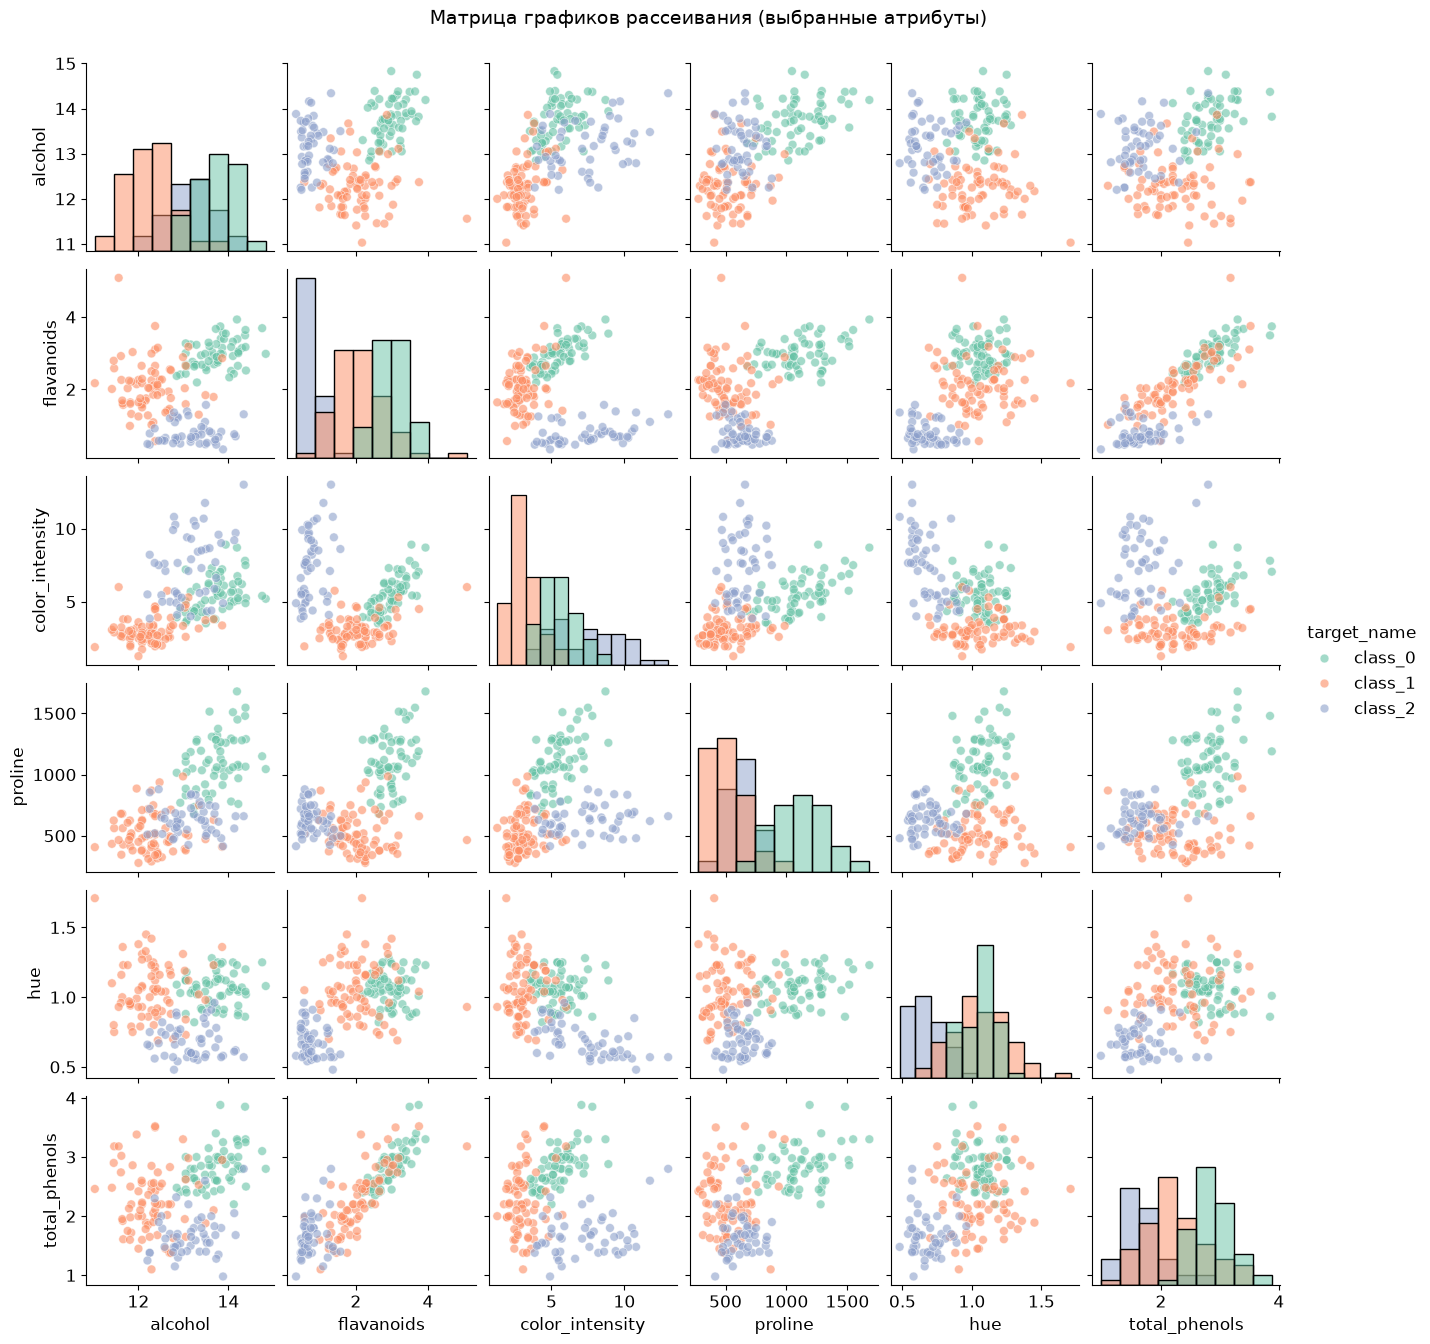

In [15]:
selected_features = ['alcohol', 'flavanoids', 'color_intensity', 'proline', 'hue', 'total_phenols']
scatter_df = df[selected_features + ['target_name']]

g = sns.pairplot(scatter_df, hue='target_name',
                 palette='Set2', diag_kind='hist',
                 plot_kws={'alpha': 0.6, 's': 40},
                 height=2.2)
g.fig.suptitle('Матрица графиков рассеивания (выбранные атрибуты)', fontsize=14, y=1.02)
plt.show()

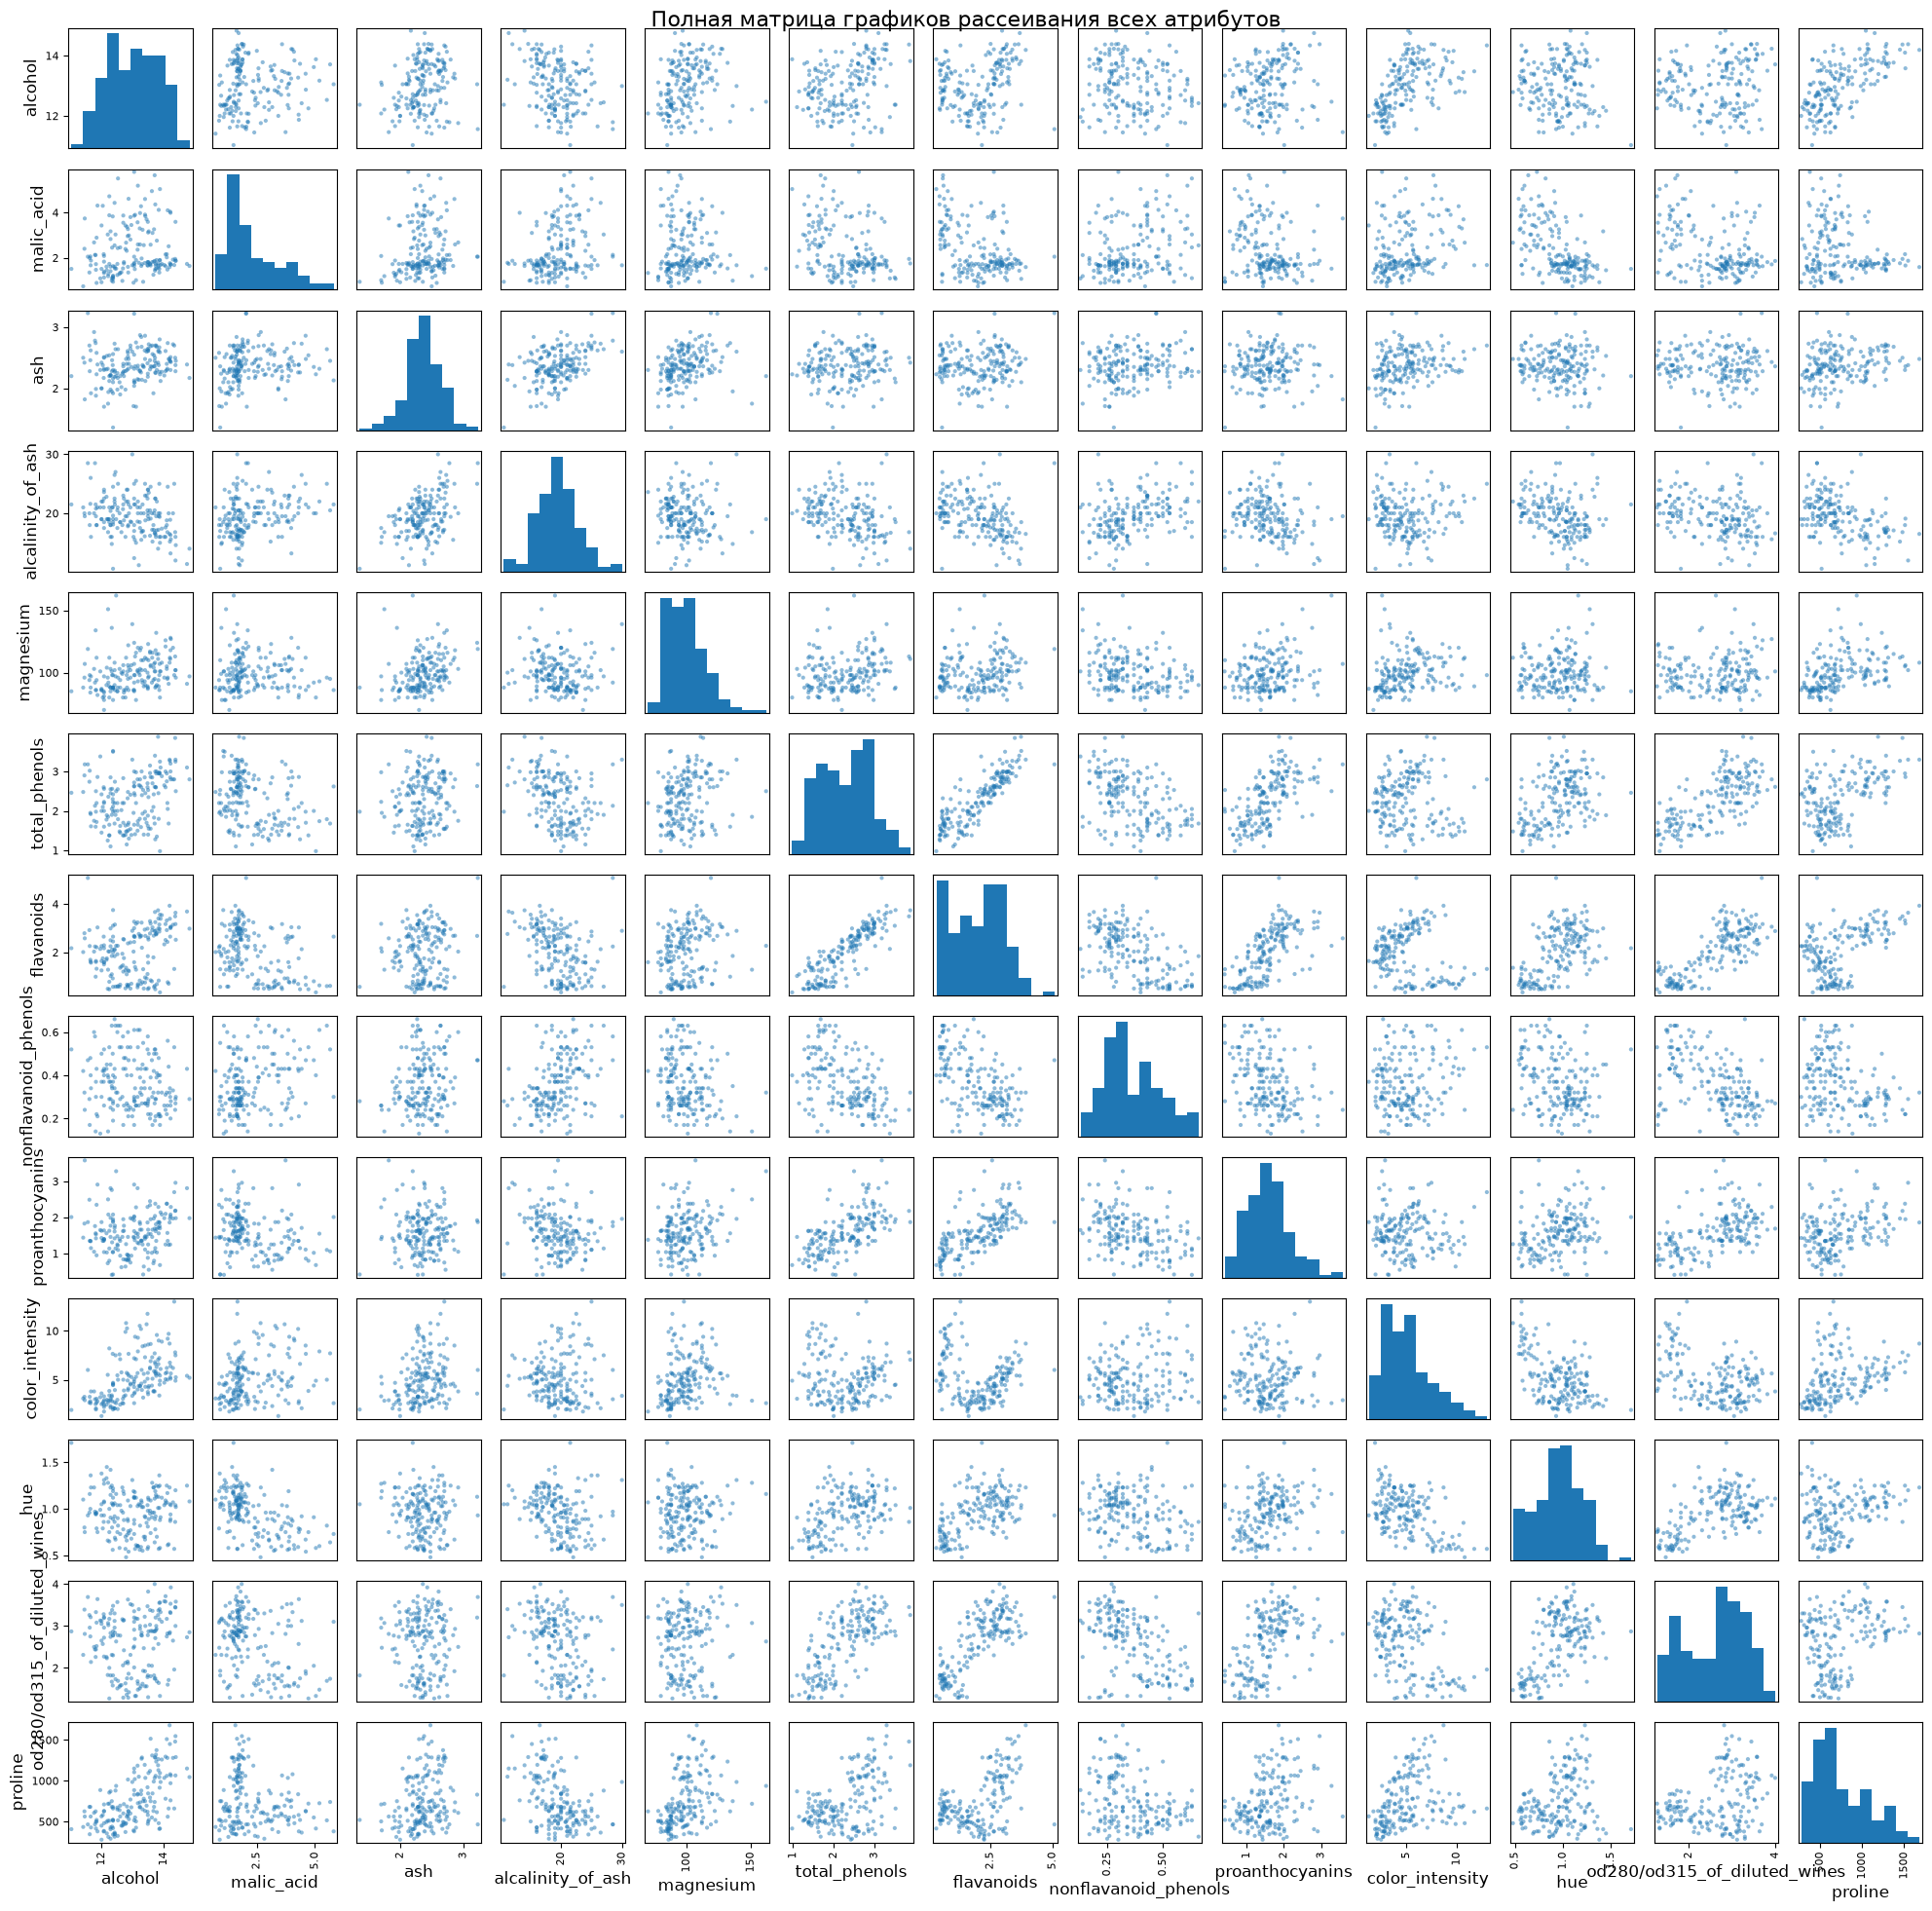

In [16]:
scatter_matrix(df_features, alpha=0.5, figsize=(20, 20), diagonal='hist')
plt.suptitle('Полная матрица графиков рассеивания всех атрибутов', fontsize=16)
plt.tight_layout()
plt.show()

### 3.4. Анализ результатов корреляционного анализа

**Основные выводы:**

1. Группа фенольных соединений (total_phenols, flavanoids, od280/od315) демонстрирует сильную взаимную положительную корреляцию. Это объясняется биохимической природой данных веществ (флавоноиды являются подклассом фенолов, а оптическая плотность при 280 нм чувствительна к фенольным соединениям);

2. На графиках рассеивания видно, что комбинации атрибутов (flavanoids и color_intensity, alcohol и proline) позволяют визуально разделить три класса вин. Это свидетельствует о хорошей разделимости классов и перспективности задачи классификации;

3. Некоррелированные атрибуты (Пр. - ash) вносят уникальную информацию и могут быть полезны для повышения точности классификации;

4. Высокая корреляция в группе фенольных соединений может вызвать проблемы мультиколлинеарности в линейных моделях.

## 4. Выводы

В ходе выполнения задания было проведено исследование датасета Wine:

1. Датасет Wine содержит 178 образцов вин трёх сортов, описанных 13 числовыми атрибутами химического анализа;

2. Статистический анализ показал, что атрибуты имеют различные масштабы (от десятых долей до тысяч) и формы распределения (от нормального до асимметричного). Это указывает на необходимость нормализации данных перед применением алгоритмов машинного обучения;

3. Выбросы обнаружены в нескольких атрибутах (Пр. - magnesium, color_intensity), но их количество невелико, пропущенные значения отсутствуют;

4. Корреляционный анализ выявил группу сильно связанных признаков (фенольные соединения) и ряд независимых атрибутов, визуализация графиков рассеивания подтверждает хорошую разделимость классов.

Датасет подходит для дальнейшего исследования алгоритмов кластеризации и классификации